In [1]:
!pip install lazypredict

In [2]:
import pandas as pd
df=pd.read_csv('/content/Feature_selection_2.csv')
df

,Unnamed: 0,FP22,FP80,FP126,FP176,FP198,FP298,FP426,FP437,FP472,...,EStateFP19,EStateFP25,EStateFP28,EStateFP29,EStateFP30,EStateFP32,EStateFP34,EStateFP35,EStateFP36,EStateFP54
0,0,0,1,1,0,0,0,0,0,0,...,0,1,0,0,0,1,0,0,0,0
1,1,0,1,1,0,0,0,0,0,0,...,0,1,0,0,0,1,0,0,0,0
2,2,0,1,1,0,0,0,0,0,0,...,0,1,0,0,0,1,0,0,0,0
3,3,0,1,1,0,0,0,0,0,0,...,0,1,0,0,0,1,0,0,0,0
4,4,0,1,1,0,0,0,0,0,0,...,0,1,0,0,0,1,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
23912,23912,0,0,0,1,0,1,0,0,0,...,0,0,0,0,1,0,0,0,1,0
23913,23913,0,0,0,0,0,1,0,0,0,...,0,0,0,0,0,0,0,0,1,0
23914,23914,0,0,0,0,0,1,0,0,0,...,0,0,0,0,0,0,0,0,1,0
23915,23915,0,0,0,0,0,1,0,0,0,...,0,1,0,1,0,0,0,0,0,0


In [3]:
df.isna().sum()
df.dropna(inplace=True)

In [4]:
X = df.drop('class', axis=1)
Y = df['class']

In [5]:
Y = df['class']
Y

,class
0,0
1,0
2,0
3,0
4,0
...,...
23912,0
23913,0
23914,0
23915,0


In [6]:
!pip install dask[dataframe]

In [7]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from lazypredict.Supervised import LazyClassifier
import warnings
warnings.filterwarnings("ignore")

In [8]:
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.3, stratify=Y,random_state=100)

In [9]:
X_train.shape, Y_train.shape

((16741, 211), (16741,))

In [10]:
X_test.shape, Y_test.shape

((7176, 211), (7176,))

In [11]:
clf = LazyClassifier(verbose=0,ignore_warnings=True)
models, predictions = clf.fit(X_train, X_test, Y_train, Y_test)
models

  0%|          | 0/32 [00:00<?, ?it/s]

[LightGBM] [Info] Number of positive: 5275, number of negative: 11466
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.023436 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 2049
[LightGBM] [Info] Number of data points in the train set: 16741, number of used features: 211
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.315095 -> initscore=-0.776407
[LightGBM] [Info] Start training from score -0.776407


,Accuracy,Balanced Accuracy,ROC AUC,F1 Score,Time Taken
Model,,,,,
ExtraTreesClassifier,0.90,0.87,0.87,0.90,6.33
RandomForestClassifier,0.90,0.87,0.87,0.90,6.05
XGBClassifier,0.89,0.86,0.86,0.89,1.64
KNeighborsClassifier,0.89,0.86,0.86,0.89,3.01
BaggingClassifier,0.89,0.86,0.86,0.89,6.44
DecisionTreeClassifier,0.85,0.83,0.83,0.85,0.96
LabelSpreading,0.88,0.83,0.83,0.87,27.01
LabelPropagation,0.88,0.83,0.83,0.87,21.99
SVC,0.88,0.82,0.82,0.87,73.05


Model Label Spreading could not be evaluated. Error: Input contains NaN.
Model Label Propagation could not be evaluated. Error: Input contains NaN.
Model LightGBM could not be evaluated. Error: Do not support special JSON characters in feature name.


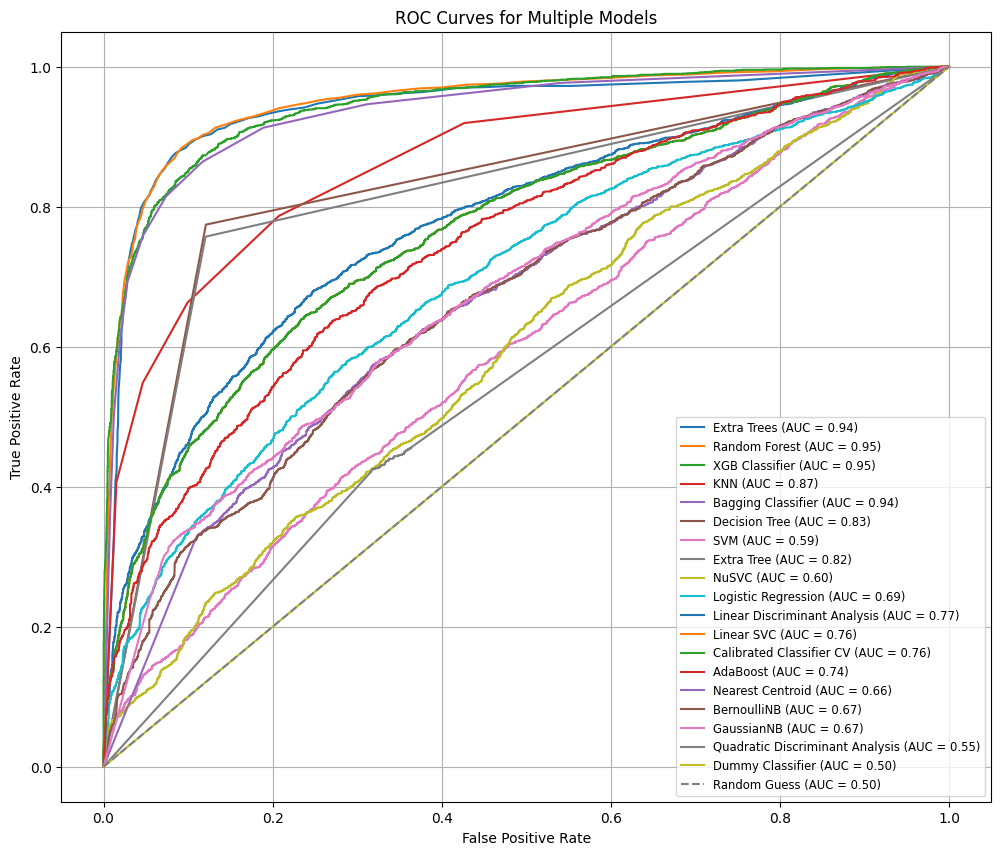

<Figure size 1000x1000 with 0 Axes>

In [15]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import label_binarize

# Import classifiers
from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    BaggingClassifier,
    AdaBoostClassifier,
)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier, ExtraTreeClassifier
from sklearn.svm import SVC, NuSVC, LinearSVC
from sklearn.linear_model import (
    LogisticRegression,
    RidgeClassifier,
    RidgeClassifierCV,
    SGDClassifier,
    PassiveAggressiveClassifier,
    Perceptron,
)
from xgboost import XGBClassifier
from sklearn.discriminant_analysis import (
    LinearDiscriminantAnalysis,
    QuadraticDiscriminantAnalysis,
)
from sklearn.calibration import CalibratedClassifierCV
from sklearn.naive_bayes import GaussianNB, BernoulliNB
from sklearn.neighbors import NearestCentroid
from sklearn.dummy import DummyClassifier
from sklearn.semi_supervised import LabelSpreading, LabelPropagation
from lightgbm import LGBMClassifier

# Define models to evaluate
models_to_evaluate = {
    "Extra Trees": ExtraTreesClassifier(),
    "Random Forest": RandomForestClassifier(),
    "XGB Classifier": XGBClassifier(),
    "KNN": KNeighborsClassifier(),
    "Bagging Classifier": BaggingClassifier(),
    "Decision Tree": DecisionTreeClassifier(),
    "Label Spreading": LabelSpreading(),
    "Label Propagation": LabelPropagation(),
    "SVM": SVC(probability=True),
    "Extra Tree": ExtraTreeClassifier(),
    "LightGBM": LGBMClassifier(),
    "NuSVC": NuSVC(probability=True),
    "Logistic Regression": LogisticRegression(),
    "Linear Discriminant Analysis": LinearDiscriminantAnalysis(),
    "Linear SVC": CalibratedClassifierCV(LinearSVC(), cv=5),
    "Ridge Classifier": RidgeClassifier(),
    "Ridge Classifier CV": RidgeClassifierCV(),
    "Calibrated Classifier CV": CalibratedClassifierCV(),
    "SGD Classifier": SGDClassifier(),
    "Perceptron": Perceptron(),
    "AdaBoost": AdaBoostClassifier(),
    "Nearest Centroid": NearestCentroid(),
    "BernoulliNB": BernoulliNB(),
    "GaussianNB": GaussianNB(),
    "Passive Aggressive": PassiveAggressiveClassifier(),
    "Quadratic Discriminant Analysis": QuadraticDiscriminantAnalysis(),
    "Dummy Classifier": DummyClassifier()
}
# Initialize a figure for the ROC plots
plt.figure(figsize=(12, 10))

# Binarize the labels for ROC curve calculation (ensure y is binary: [0, 1])
Y_bin = label_binarize(Y_test, classes=[0, 1])

# Loop through each model
for model_name, model in models_to_evaluate.items():
    try:
        # Train the model
        model.fit(X_train, Y_train)
        # Predict probabilities
        Y_proba = model.predict_proba(X_test)[:, 1] if hasattr(model, "predict_proba") else None
        if Y_proba is not None:
            # Calculate ROC curve
            fpr, tpr, _ = roc_curve(Y_test, Y_proba)
            # Calculate the AUC
            roc_auc = auc(fpr, tpr)
            # Plot the ROC curve
            plt.plot(fpr, tpr, label=f"{model_name} (AUC = {roc_auc:.2f})")
    except Exception as e:
        print(f"Model {model_name} could not be evaluated. Error: {e}")

# Plot random chance line
plt.plot([0, 1], [0, 1], color="gray", linestyle="--", label="Random Guess (AUC = 0.50)")
# Customize the plot
plt.title("ROC Curves for Multiple Models")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend(loc="lower right", fontsize='small')
plt.grid()
plt.show()
fig = plt.figure(figsize=(10, 10))
plt.savefig("roc_lc.jpg", bbox_inches = 'tight')

Model Label Spreading could not be evaluated. Error: Input contains NaN.
Model Label Propagation could not be evaluated. Error: Input contains NaN.
Model LightGBM could not be evaluated. Error: Do not support special JSON characters in feature name.


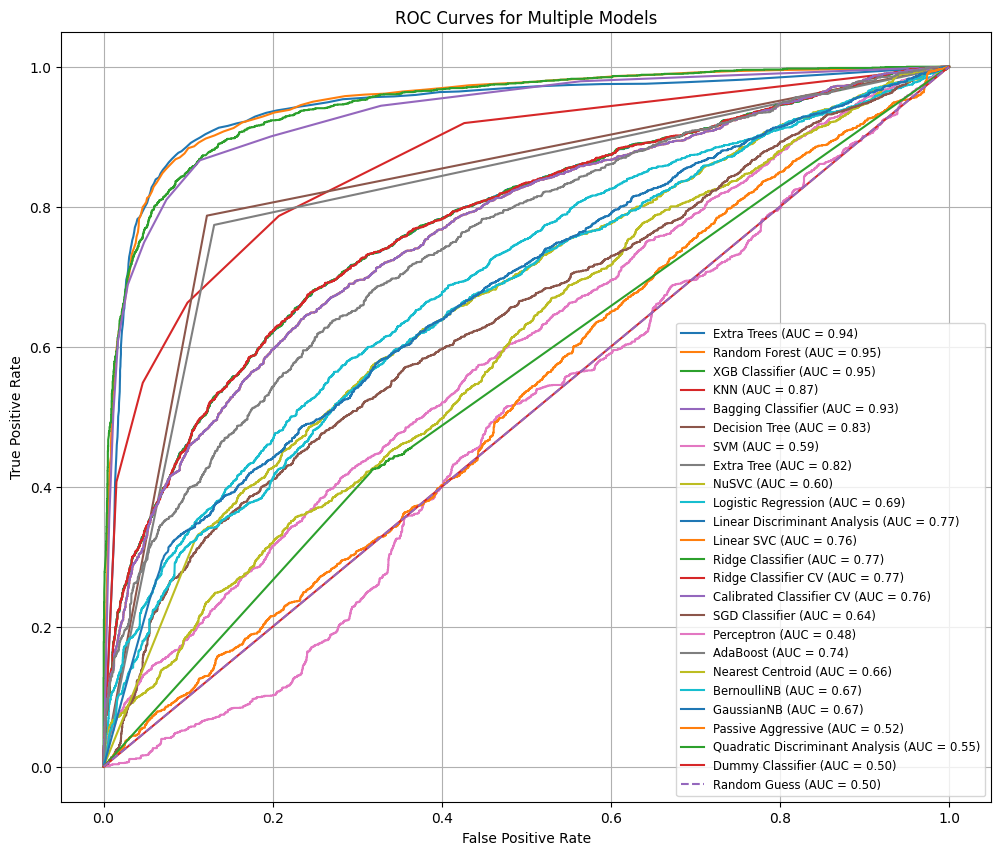

In [16]:
# Initialize a figure for the ROC plots
plt.figure(figsize=(12, 10))

# Loop through each model
for model_name, model in models_to_evaluate.items():
    try:
        model.fit(X_train, Y_train)

        # Predict probabilities
        if hasattr(model, "predict_proba"):
            Y_proba = model.predict_proba(X_test)[:, 1]
        elif hasattr(model, "decision_function"):
            Y_proba = model.decision_function(X_test)
        else:
            Y_proba = None

        if Y_proba is not None:
            fpr, tpr, _ = roc_curve(Y_test, Y_proba)
            roc_auc = auc(fpr, tpr)
            plt.plot(fpr, tpr, label=f"{model_name} (AUC = {roc_auc:.2f})")

    except Exception as e:
        print(f"Model {model_name} could not be evaluated. Error: {e}")

# Random chance line
plt.plot([0, 1], [0, 1], linestyle="--", label="Random Guess (AUC = 0.50)")

# Labels and formatting
plt.title("ROC Curves for Multiple Models")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend(loc="lower right", fontsize='small')
plt.grid()

# ✅ SAVE BEFORE SHOW
plt.savefig("roc_lc.jpg", dpi=300, bbox_inches="tight")

# Then show
plt.show()
